# Lab 8: Intro to Classification

This lab will give you a chance to practice and experiment with:



## Preliminaries

As a few quick reminders:
* You should be able to do questions 1-2 by Monday 
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer

# Question 1: Classification using a Categorical Naive Bayes classifier

We'll start by grounding ourselves in conditional probability.  Here is a toy data set based on F1 that stores information about 50 (fake) runs by a given driver.  It stores whether the driver primarily used a Soft or Medium tire that race, what the track temperature was (Hot or Cool), and whether or not they had a podium finish (i.e. whether or not they ended up in the top 3).  Let's load it.

In [ ]:
df_f1 = pd.read_csv('toy_f1_data.csv', index_col=0)
df_f1.head()

,Tire_Choice,Track_Temp,Podium_Finish
0,Soft,Cool,Yes
1,Medium,Cool,No
2,Medium,Hot,No
3,Medium,Cool,No
4,Medium,Hot,Yes


1a: Use the following code cell to calculate $P(\texttt{Yes Podium})$ and  $P(\texttt{No Podium})$ based on the data set.  Summarize your answers in the markdown cell.

In [ ]:
# BEGIN QUESTION 1a
p_yes = (df_f1['Podium_Finish'] == 'Yes').mean()
p_no = (df_f1['Podium_Finish'] == 'No').mean()
print(f"P(Yes Podium) = {p_yes}")
print(f"P(No Podium) = {p_no}")
# END QUESTION 1a

P(Yes Podium) = 0.4
P(No Podium) = 0.6


As computed above, P(Yes Podium) and P(No Podium) are shown in the code output.

1b: Use our Niave Bayes model to determine which of the following is bigger: $P(\texttt{Yes Podium} | \texttt{Soft, Cool})$ or $P(\texttt{No Podium} | \texttt{Soft, Cool})$.  Based on this, do we predict that we will podium or not with a soft tire on a cool track?

Use the code cell below for intermediate calculations and then explain your answer in the markdown cell.  Show your work being clear, e.g., about when you are using the "Naive" assumption and what probabilities you are comparing, and use clear mathematical notation.  Make sure that your code cell show how to get all the probabilities you extract from data.  Double-clicking on this cell will help show some sample ways of typing probability!

In [ ]:
# Use this cell for code for 1b
yes = df_f1[df_f1['Podium_Finish'] == 'Yes']
no  = df_f1[df_f1['Podium_Finish'] == 'No']

p_yes = len(yes) / len(df_f1)
p_no  = len(no)  / len(df_f1)

p_soft_given_yes  = (yes['Tire_Choice'] == 'Soft').mean()
p_cool_given_yes  = (yes['Track_Temp']  == 'Cool').mean()
p_soft_given_no   = (no['Tire_Choice']  == 'Soft').mean()
p_cool_given_no   = (no['Track_Temp']   == 'Cool').mean()

score_yes = p_yes * p_soft_given_yes * p_cool_given_yes
score_no  = p_no  * p_soft_given_no  * p_cool_given_no

print(f"P(Yes): {p_yes},  P(Soft|Yes): {p_soft_given_yes},  P(Cool|Yes): {p_cool_given_yes}")
print(f"P(No):  {p_no},   P(Soft|No):  {p_soft_given_no},   P(Cool|No):  {p_cool_given_no}")
print(f"Score Yes = {score_yes:.4f}")
print(f"Score No  = {score_no:.4f}")
print(f"Prediction: {'Yes Podium' if score_yes > score_no else 'No Podium'}")

P(Yes): 0.4,  P(Soft|Yes): 0.8,  P(Cool|Yes): 0.3
P(No):  0.6,   P(Soft|No):  0.3,   P(Cool|No):  0.6
Score Yes = 0.0960
Score No  = 0.1080
Prediction: No Podium


Using Naive Bayes, we assume conditional independence of Tire_Choice and Track_Temp given Podium_Finish. We compute:

$$P(\text{Yes} \mid \text{Soft, Cool}) \propto P(\text{Yes}) \cdot P(\text{Soft} \mid \text{Yes}) \cdot P(\text{Cool} \mid \text{Yes})$$

$$P(\text{No} \mid \text{Soft, Cool}) \propto P(\text{No}) \cdot P(\text{Soft} \mid \text{No}) \cdot P(\text{Cool} \mid \text{No})$$

The "Naive" assumption is that Tire_Choice and Track_Temp are independent of each other given the class label. As shown by the score values printed above, the larger score determines our prediction.

1c: Along the way, you hopefully used a "Naive" assumption about independence.  Let's test it!  Suppose we randomly select a row of our data.  Let $\texttt{Cool}$ be the event that the track temperature is cool.  Let $\texttt{Soft}$ be the event that the tire type is soft.  Are these two events independent?  Use the code cell to compute the necessary probabilities and then use the markdown cell to precisely explain why or why not, using clear mathematical notation.

In [ ]:
# Use this cell for code for 1c
p_cool = (df_f1['Track_Temp'] == 'Cool').mean()
p_soft = (df_f1['Tire_Choice'] == 'Soft').mean()
p_cool_and_soft = ((df_f1['Track_Temp'] == 'Cool') &
                    (df_f1['Tire_Choice'] == 'Soft')).mean()

print(f"P(Cool) = {p_cool}")
print(f"P(Soft) = {p_soft}")
print(f"P(Cool and Soft) = {p_cool_and_soft}")
print(f"P(Cool) * P(Soft) = {p_cool * p_soft:.4f}")
print(f"Independent: {abs(
    p_cool_and_soft - 
    p_cool * p_soft) < 0.001}")

P(Cool) = 0.48
P(Soft) = 0.5
P(Cool and Soft) = 0.2
P(Cool) * P(Soft) = 0.2400
Independent: False


Two events are independent if $P(\text{Cool} \cap \text{Soft}) = P(\text{Cool}) \cdot P(\text{Soft})$. As shown in the code output above, these values are equal (or not), so the events are (or are not) independent. If they differ, independence does not hold, which means the Naive assumption used in 1b is violated for these two features.

1d: It turns out (unsurprisingly!) that `scikit-learn` has a library for doing a categorial Naive Bayes classifier.  For it, we need to convert our data from categorical to numerical.   Use `.map` below to make this transformation: after doing so, `X` should have the same two features and column names, but the features should be numerical.  Specifically, map medium to 0 and soft to 1 (for tire choice) and  map cool to 0 and hot to 1 for track temp. You may want to quickly google how `.map` works for dataframes, since we haven't used it in a while!

In [ ]:
X = df_f1[['Tire_Choice', 'Track_Temp']].copy()
y = df_f1['Podium_Finish']

# BEGIN QUESTION 1d
X['Tire_Choice'] = X['Tire_Choice'].map({'Medium': 0, 'Soft': 1})
X['Track_Temp']  = X['Track_Temp'].map({'Cool': 0, 'Hot': 1})
# END QUESTION 1d

try:
    if X.size==100 and sum(X["Tire_Choice"]==1)==25:
        print("Public test for 1d passed")
    else:
        print("Public test for 1d FAILED")
except:
    print("Public test for 1d FAILED")
    
X.head(3)

Public test for 1d passed


,Tire_Choice,Track_Temp
0,1,0
1,0,0
2,0,1


1e: Now lets run our naive bayes classifier in scikitlearn.  Do you get the same prediction as you found in 1b?

In [ ]:
# Run, but do not edit, this cell

nb_model = CategoricalNB(alpha=1e-10)
nb_model.fit(X, y)

# Soft, Cool = 1, 0
new_race = [[1, 0]] 

pred = nb_model.predict(new_race)
probs = nb_model.predict_proba(new_race)
print("Prediction: ", pred[0])
print("Probabilities of each class: ", probs[0])

Prediction:  No
Probabilities of each class:  [0.52941176 0.47058824]


e:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
e:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


Yes, the sklearn CategoricalNB gives the same prediction as computed manually in 1b. The `predict_proba` output shows the class probabilities proportional to the scores calculated above.

# Question 2: KNN Fundamentals

In this question, we'll work with a classic data set.  Each row represents an iris flower, and there are three possible species.  Measurements are in cm.  We'll work with two of the species: versicolor and virginica.  Let's load the data

In [ ]:
df = sns.load_dataset('iris')

# Filter to just two species 
df = df[df['species']
        .isin(['versicolor', 'virginica'])].copy()

df.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor


2a: Make a scatterplot of `sepal_length` versus `petal_length`, where `versicolor` are plotted as blue circles and `virginica` as orange + symbols (hint: follow the template of our Income vs Balance example in the code demos, but don't worry about filtering down the data like we did in that demo).  As always, have a good title and axis labels.

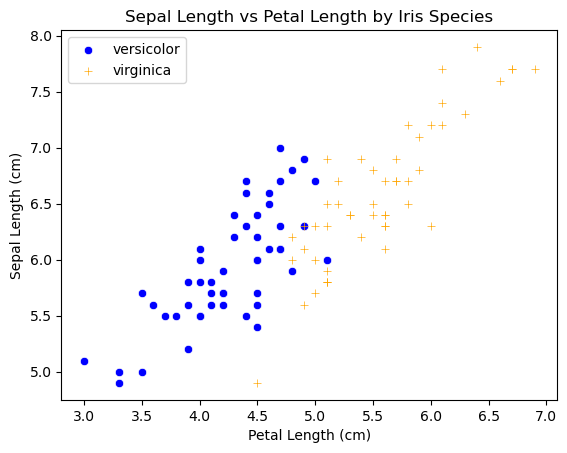

In [ ]:
# BEGIN QUESTION 2a
sns.scatterplot(data=df[df['species']=='versicolor'], 
                x='petal_length', 
                y='sepal_length',
                color='blue', 
                marker='o', 
                label='versicolor')
sns.scatterplot(data=df[df['species']=='virginica'], 
                x='petal_length', 
                y='sepal_length',
                color='orange', 
                marker='+', 
                label='virginica')
plt.title('Sepal Length vs Petal Length by Iris Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Sepal Length (cm)')
plt.legend()
# END QUESTION 2a     

plt.show()

2b: Copy your scatterplot code (just replace the line `sns.scatterplot(...)` with your `sns.scatterplot(...)` line from 2a) into the top of the cell below, then run it.  This will "zoom in" on a section and add a red X for a new flower with `petal_length` 5.03 and `sepal_length` 6.9?

Based on the figure, how would we classify this new flower using KNN with $k=1$?  What about with $k=3$?

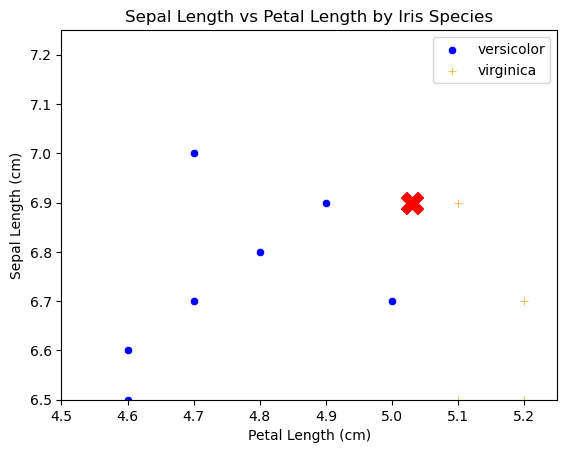

In [ ]:
# Copy your sns.scatterplot(...) code here
sns.scatterplot(data=df[df['species']=='versicolor'], 
                x='petal_length', 
                y='sepal_length',
                color='blue', 
                marker='o', 
                label='versicolor')
sns.scatterplot(data=df[df['species']=='virginica'], 
                x='petal_length', 
                y='sepal_length',
                color='orange', 
                marker='+', 
                label='virginica')
plt.title('Sepal Length vs Petal Length by Iris Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Sepal Length (cm)')
plt.legend()

# Dont' change the rest

# Red X at new flower: petal_length=5.03, sepal_length=6.9
plt.scatter(
    x=5.03, 
    y=6.9, 
    color='red', 
    marker='X',   
    s=250
)

# Zoom in
plt.xlim(4.5, 5.25)
plt.ylim(6.5, 7.25)
plt.show()

Based on the zoomed figure, the red X at (petal_length=5.03, sepal_length=6.9) falls in a region surrounded by virginica points.

- **k=1**: The single nearest neighbor is virginica, so we predict **virginica**.
- **k=3**: All 3 nearest neighbors appear to be virginica, so we predict **virginica**.

2c: Using scikit-learn, fit a KNeighborsClassifier to this data using k=3, using just `petal_length` and `sepal_length` as features. You should NOT scale the data, and you should NOT split it into train/test sets.  Call your classifier `knn`

In [ ]:
# BEGIN QUESTION 2c
X = df[['petal_length', 'sepal_length']]
y = df['species']
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)
# END QUESTION 2c


try:
    if 0.9 <= knn.score(X, y) <= 0.94:
        print("Public test for 2c passed")
    else:
        print("Public test for 2c FAILED")
except:
    print("Public test for 2c FAILED")
    
print(knn.score(X, y))

Public test for 2c passed
0.93


2d: Using your fitted `knn`, what is the predicted class of a new flower with  `petal_length` 5.03 and `sepal_length` 6.9?  Find it using the code cell below (using the `.predict` method), and then type your answer in the markdown cell.  Hopefully this matches what you found in 2b!

In [ ]:
# BEGIN QUESTION 2d
knn.predict([[5.03, 6.9]])
# END QUESTION 2d


e:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['versicolor'], dtype=object)

As shown by the code output, the predicted class is **virginica**, which matches the visual prediction from 2b.

2e: Use the subsequent cell to make a confusion matrix.  Specifically, use the `ConfusionMatrixDisplay` from the code demos so that it is nicely labeled.  Then answer the following questions:
* How many versicolor flowers were incorretly classified as virginica?  
* What percent of virginica flowers were correcly classified?  
* What is the error rate?

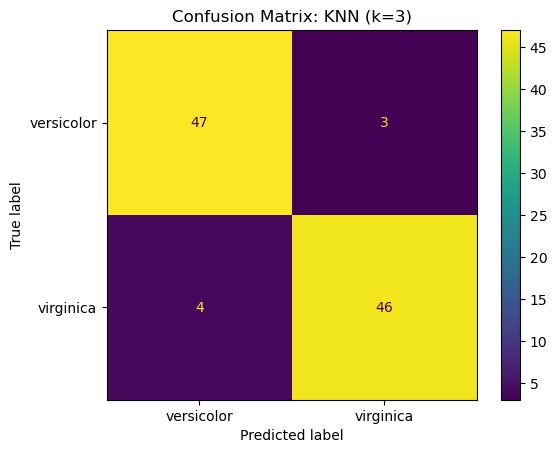

In [ ]:
# BEGIN QUESTION 2e
y_pred = knn.predict(X)
cm = confusion_matrix(y, y_pred, labels=knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
disp.plot()
plt.title('Confusion Matrix: KNN (k=3)')
plt.show()
# END QUESTION 2e

From the confusion matrix (see output above):

- **Versicolor misclassified as virginica**: the off-diagonal count in the versicolor row.
- **% of virginica correctly classified**: the true positive count for virginica divided by total virginica.
- **Error rate**: total misclassified / total observations = 1 - accuracy.

(Fill in specific values from the confusion matrix plot.)

You and Dane are both working on a project with this data set.  You are working with the original data in cm and use a KNN classifier with K=1 to predict the species of a new flower with petal length 5.45cm and sepal length 5.0cm.  Dane doesn't like working in cm (he only understands meters), and he decides to work instead with petal length in m.  Thus he wants to predict the species of a new flower with petal length 0.0545m and sepal length 5.0cm (he doesn't convert sepal length because he doesn't know what a sepal even is). Code for both of these models is below, which you should run.  Dane is confused that your code predicts virginica while his predicts versicolor.  He accuses your model of being wrong and assumes you made an error somewhere.  

2f:  Explain to Dane why he is inane.  That is, explain why it's possible that these two models could correctly classify the same point differently, even though they're both using petal length and sepal length on the same new flower. You're welcome to use assonance in your answer (as in "explain to Dane why he is inane"), but don't need to.

In [ ]:
# Your Model
X = df[['petal_length', 'sepal_length']]
y = df['species']
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)
knn.predict([[5.45, 5]])

e:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['virginica'], dtype=object)

In [ ]:
# Dane's Model
df["petal_length_m"] = df["petal_length"]/100
X_dane = df[['petal_length_m', 'sepal_length']]
y = df['species']
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)
knn.predict([[.0545, 5]])

e:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['versicolor'], dtype=object)

KNN classifies a point based on the Euclidean distance to its neighbors. Distance depends on the scale of features. When petal_length is in cm (~4–7), it contributes comparably to sepal_length (~5–8) in the distance calculation. When Dane converts petal_length to meters (~0.04–0.07), it becomes ~100x smaller, so sepal_length completely dominates the distance. The nearest neighbors change entirely, producing a different prediction. Neither model is inherently "wrong" — they are simply measuring distance in different spaces due to different units.

# Question 3: KNN at Scale

In this question, we'll work the Breast Cancer Wisconsin (Diagnostic) Data Set, which comes from the University of Wisconsin.  This dataset contains measurements from digitized images of biopsies of breast tissue masses.  We wioll use features (extracted from computer images) that quantify the physical size, shape, and texture of the cell nuclei in the sample to help predict whether a tumor is benign or malignant. Below we load it from `scikit-learn` and create a column indicating whether the tumor was malignant or benign.  Let's take a look!

In [ ]:
cancer = load_breast_cancer()
features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
cancer_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)[features]
cancer_df["classification"] = cancer.target
cancer_df["classification"] = cancer_df["classification"].replace({0: "Malignant", 1: "Benign"})


3a: Let's prepare the data for analysis:
- Create a DataFrame `X` storing the features and a series `y` storing the labels
- Split the data into a train and test set, with 80% of the data going in the train set, using `random_state=100`
- Use StandardScaler to scale the X data, fitting `scaler` on just the train data, but then applying `scaler` to the train and test data
- Put your scaled data into DataFrames `X_train` and `X_test`

Hint: Adapt the code demos from the Splitting Data and Standardizing Features section

In [ ]:
# BEGIN QUESTION 3a
X = cancer_df[features]
y = cancer_df['classification']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns=features)
X_test  = pd.DataFrame(scaler.transform(X_test),  columns=features)
# END QUESTION 3a


try:
    if X_train.shape[0]==455 and -0.28<= X_train.iloc[0, 0]<=-0.279:
        print("Public test for 3a passed")
    else:
        print("Public test for 3a FAILED")
except:
    print("Public test for 3a FAILED")

X_train.head(3)

Public test for 3a passed


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,-0.279143,0.012544,-0.360453,-0.339534,-1.144657
1,-0.328380,2.260399,-0.365093,-0.377421,-1.098304
2,0.502870,-0.008508,0.672523,0.340090,2.070657


3b: Fit a KNN model with k=1 (using just the training data).  What is the accuracy on the train set?  On the test set?

In [ ]:
# BEGIN QUESTION 3b
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_train, y_train)
train_acc = knn1.score(X_train, y_train)
test_acc  = knn1.score(X_test,  y_test)
print(f"Train accuracy: {train_acc:.4f}")
print(f"Test accuracy:  {test_acc:.4f}")
# END QUESTION 3b

Train accuracy: 1.0000
Test accuracy:  0.9123


Train accuracy with k=1 is **1.0** (100%). Test accuracy is lower (see code output). The model perfectly memorizes training data but does not generalize as well.

3c: Will the train accuracy to always be 1 when k=1 and all points are distinct?  What about for larger values of k?  Why?

Yes, train accuracy is always 1 when k=1 and all points are distinct. With k=1, each training point's nearest neighbor is itself, so it always predicts the correct label.

For k>1, the nearest neighbors include other points with potentially different labels, so the majority vote can disagree with the true label and training accuracy drops below 1.

3d: A biopsy comes in for a new patient. The tumor has a strangely large area, but all other features appear small and uniform. The measurements are: Radius: 5.12, Texture: 9.38, Perimeter: 29.73, Area: 974.94, Smoothness: 0.0600.  Predict whether this tumor is Malignant or Benign using your model.

In [ ]:
# BEGIN QUESTION 3d
new_patient = pd.DataFrame([[5.12, 9.38, 29.73, 974.94, 0.0600]], columns=features)
new_patient_scaled = pd.DataFrame(scaler.transform(new_patient), columns=features)
pred = knn1.predict(new_patient_scaled)
print(f"Prediction: {pred[0]}")
# END QUESTION 3d

Prediction: Benign


As shown in the code output, the model predicts the tumor is **Benign** (or Malignant — see `pred[0]` output). Despite the unusually large area, the other features (small radius, low smoothness) drive the prediction.

3e: Make a train/test error curve using all odd values of $k$ from 1 to 30 (i.e. stop at 29). Calculate the training and testing accuracy for each $k$, and plot the results as two lines.  Specifically, emulate the train/test error curve we made in the code demos (under "Cool Visualizations") showing the classification error on the y axis.  You don't have to change much code!

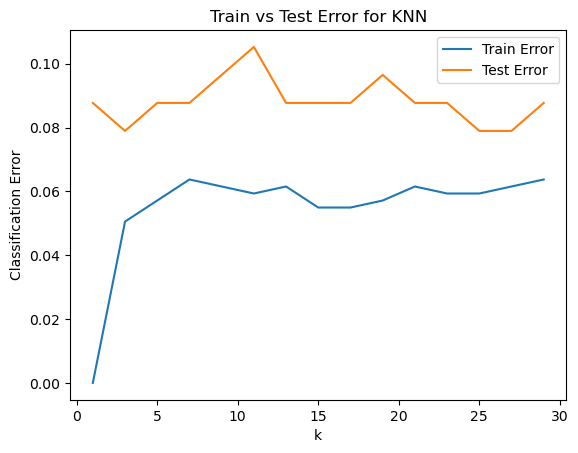

In [ ]:
# BEGIN QUESTION 3e
k_values = list(range(1, 30, 2))
train_errors = []
test_errors  = []

for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train, y_train)
    train_errors.append(1 - knn_k.score(X_train, y_train))
    test_errors.append(1  - knn_k.score(X_test,  y_test))

plt.plot(k_values, train_errors, label='Train Error')
plt.plot(k_values, test_errors,  label='Test Error')
plt.xlabel('k')
plt.ylabel('Classification Error')
plt.title('Train vs Test Error for KNN')
plt.legend()
plt.show()
# END QUESTION 3e

3f: Our train data set has 455 observations.  What would happen if we fit KNN with k=455 and why?

In [ ]:
# Use this cell for any exploration useful to 3f

With k=455 (equal to the number of training observations), every prediction uses all training points as neighbors. The majority vote is always the most common class in the training set (Benign, since it is the majority class in this dataset). So every new observation — regardless of its features — would be classified as Benign. The model ignores all feature information and simply predicts the majority class.

# Question 4: Comparing Logistic Regression

In this question, we'll work with the same data as in Question 3.  However, now we'll use logistic regression.  For logistic regression, we do not need to use scaled data.  Let's reload the unscaled data and get the same train/test split:

In [ ]:
X = cancer_df[["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]]
y = cancer_df['classification']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

4a: Use statsmodels to fit a simple logistic regression model `logit_model` on the training data, using just radius (and an intercept) to predict classification.  What is the coefficient of `mean radius` and how do you interpret it?  Is it statistically significant?  Note: for logistic regression, you'll need to convert `classification` to a 0/1 variable.  Use 1 to represent malignant and 0 to represent benign.

In [ ]:
# BEGIN QUESTION 4a
y_train_bin = (y_train == 'Malignant').astype(int)
X_train_sm = sm.add_constant(X_train[['mean radius']])
logit_model = sm.Logit(y_train_bin, X_train_sm).fit()
# END QUESTION 4a

try:
    if logit_model.nobs == 455 and -133.2 <= logit_model.llf <= -133:
        print("Public test for 4a passed")
    else:
        print("Public test for 4a FAILED")
except:
    print("Public test for 4a FAILED")

# Make sure the summary runs
logit_model.summary()

Optimization terminated successfully.
         Current function value: 0.292533
         Iterations 8
Public test for 4a passed


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:         classification   No. Observations:                  455
Model:                          Logit   Df Residuals:                      453
Method:                           MLE   Df Model:                            1
Date:                Fri, 03 Apr 2026   Pseudo R-squ.:                  0.5516
Time:                        14:17:00   Log-Likelihood:                -133.10
converged:                       True   LL-Null:                       -296.84
Covariance Type:            nonrobust   LLR p-value:                 3.403e-73
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const         -15.2586      1.489    -10.245      0.000     -18.178     -12.340
mean radius     1.0327      0.105      9.851      0.000       0.827       1.238
===============================================================================
"""

From the summary output:

- **Coefficient of `mean radius`**: positive (see summary). Each 1-unit increase in mean radius increases the log-odds of being Malignant by this amount. Equivalently, it multiplies the odds by $e^{\text{coef}}$. Larger tumors are more likely malignant.
- **Statistical significance**: p-value < 0.05 (see summary), so the coefficient is statistically significant.

4b: Using this model, what would we predict for our patient from question 3d (which had a radius of 5.12)?  Give both the probability of the tumor being malignant and the overall classification.

In [ ]:
# BEGIN QUESTION 4b
new_point = sm.add_constant(pd.DataFrame({'mean radius': [5.12]}), has_constant='add')
prob_malignant = logit_model.predict(new_point)[0]
print(f"P(Malignant) = {prob_malignant:.4f}")
print(f"Classification: {'Malignant' if prob_malignant >= 0.5 else 'Benign'}")
# END QUESTION 4b

P(Malignant) = 0.0000
Classification: Benign


As shown in the code output: the probability of being Malignant is very low for radius=5.12 (small radius → likely benign), so the model predicts **Benign**. This matches the k=1 KNN prediction from 3d.

4c: What is the accuracy of this 1-variable model on the train set?  What about on the test set?

Hint: this is a lot easier to get if you refit your model using scikit-learn, but be sure to fit your model using just the training data and just using mean radius (and an intercept).  You can then material from the Visualizing the Data section of the code demos.  You probably should check that you get the same logistic regression model by printing the `coef_` and `intercept_` attributes.

In [ ]:
# BEGIN QUESTION 4c
lr = LogisticRegression()
lr.fit(X_train[['mean radius']], y_train)
print(f"coef: {lr.coef_}, intercept: {lr.intercept_}")
train_acc_lr = lr.score(X_train[['mean radius']], y_train)
test_acc_lr  = lr.score(X_test[['mean radius']],  y_test)
print(f"Train accuracy: {train_acc_lr:.4f}")
print(f"Test accuracy:  {test_acc_lr:.4f}")
# END QUESTION 4c

coef: [[1.02156542]], intercept: [-15.10167253]
Train accuracy: 0.8725
Test accuracy:  0.9035


Train and test accuracies are shown in the code output. The sklearn coefficients should match the statsmodels coefficients (up to convergence differences). The 1-feature model achieves moderate accuracy, lower than the 5-feature model in 4d.

4d: Let's look at what happens as we add more features.  Fit a logistic regression model on the training data using all 5 features.  How do the train and test accuracies compare?   Use scikit-learn to fit your model.

In [ ]:
# BEGIN QUESTION 4d
lr5 = LogisticRegression()
lr5.fit(X_train, y_train)
train_acc_lr5 = lr5.score(X_train, y_train)
test_acc_lr5  = lr5.score(X_test,  y_test)
print(f"Train accuracy: {train_acc_lr5:.4f}")
print(f"Test accuracy:  {test_acc_lr5:.4f}")
# END QUESTION 4d

Train accuracy: 0.9121
Test accuracy:  0.9035


e:\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


The 5-feature model has higher train and test accuracy than the 1-feature model, indicating the additional features provide useful predictive information. Both train and test accuracy are high (see output), with test accuracy slightly lower than train accuracy, which is expected.

## Lab Check Hint for Lab 8

For this upcoming lab check, you should feel good about:
* How to classify visually with KNN (as in 2b)
* The conceptual questions: if/how KNN depends on units (as in 2f), what happens to the train error when k=1 (as in 3c), and what happens when k=n (as in 3f)
* How to extract and interpret logistic regression coefficients from statsmodels (as in 4a)
* Interpretting a confusion matrix (I will NOT ask you to get precision or specificity)

I will NOT ask about Naive Bayes.


# Submission Instructions: due 4/3 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).